# Projekt: Predykcja emisji hałasu profilu lotniczego (Airfoil Self-Noise)
## Zastosowanie metod inteligencji obliczeniowej jako modelu zastępczego (Surrogate Model) dla symulacji numerycznych (BEM/CFD)

### 1. Wprowadzenie i cel projektu
W mechanice płynów oraz wibroakustyce numeryczne wyznaczanie pola akustycznego (np. za pomocą Metody Elementów Brzegowych - BEM rozwiązującej równanie falowe Helmholtza lub metod CFD) jest operacją wysoce kosztowną obliczeniowo.

**Cel projektu:**
Wykorzystanie metod analizy danych oraz uczenia maszynowego w języku Python do stworzenia szybkiego modelu predykcyjnego (tzw. *Surrogate Model* / cyfrowy bliźniak). Model ma za zadanie przewidywać poziom ciśnienia akustycznego (SSPL) generowanego przez profil skrzydła na podstawie parametrów aerodynamicznych i geometrycznych.


### 2. Pobranie danych
Do analizy wykorzystano zbiór danych NASA z repozytorium UCI Machine Learning Repository (`id=291`). Dane zostały pozyskane z oficjalnego API biblioteki `ucimlrepo`.

In [4]:
!pip install ucimlrepo -q

from ucimlrepo import fetch_ucirepo
import pandas as pd
import numpy as np

airfoil_self_noise = fetch_ucirepo(id=291)

X_raw = airfoil_self_noise.data.features
y_raw = airfoil_self_noise.data.targets

df = pd.concat([X_raw, y_raw], axis=1)

df.columns = [
    'Frequency',
    'Angle_of_attack',
    'Chord_length',
    'Free_stream_velocity',
    'Suction_side_displacement_thickness',
    'SSPL'
]

df.head()



[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


,Frequency,Angle_of_attack,Chord_length,Free_stream_velocity,Suction_side_displacement_thickness,SSPL
0,800,0.0,0.3048,71.3,0.002663,126.201
1,1000,0.0,0.3048,71.3,0.002663,125.201
2,1250,0.0,0.3048,71.3,0.002663,125.951
3,1600,0.0,0.3048,71.3,0.002663,127.591
4,2000,0.0,0.3048,71.3,0.002663,127.461


### 3. Weryfikacja jakości danych i czyszczenie
W tym kroku sprawdzamy spójność typów danych, występowanie brakujących wartości (NaN) oraz podstawowe wymiary zbioru.

In [5]:
print(f"Liczba obserwacji (wierszy): {df.shape[0]}")
print(f"Liczba cech (kolumn): {df.shape[1]}")
print("\n--- Informacje o typach danych i brakach ---")
df.info()

print("\n--- Liczba brakujących wartości w poszczególnych kolumnach ---")
print(df.isnull().sum())

Liczba obserwacji (wierszy): 1503
Liczba cech (kolumn): 6

--- Informacje o typach danych i brakach ---
<class 'pandas.DataFrame'>
RangeIndex: 1503 entries, 0 to 1502
Data columns (total 6 columns):
 #   Column                               Non-Null Count  Dtype  
---  ------                               --------------  -----  
 0   Frequency                            1503 non-null   int64  
 1   Angle_of_attack                      1503 non-null   float64
 2   Chord_length                         1503 non-null   float64
 3   Free_stream_velocity                 1503 non-null   float64
 4   Suction_side_displacement_thickness  1503 non-null   float64
 5   SSPL                                 1503 non-null   float64
dtypes: float64(5), int64(1)
memory usage: 70.6 KB

--- Liczba brakujących wartości w poszczególnych kolumnach ---
Frequency                              0
Angle_of_attack                        0
Chord_length                           0
Free_stream_velocity               

Zbiór danych składa się z 1503 pomiarów. Wszystkie cechy są typu zmiennoprzecinkowego (`float64`) lub całkowitego (`int64`). Nie stwierdzono obecności brakujących wartości (NaN), co oznacza brak konieczności imputacji danych.

### 4. Inżynieria cech (Feature Engineering) z wiedzą dziedzinową
Standardowy zbiór zawiera wyłącznie proste wielkości wymiarowe. W mechanice płynów i wibroakustyce kluczową rolę odgrywają bezwymiarowe liczby kryterialne oraz charakterystyka logarytmiczna:

1. **Liczba Strouhala ($St$):** Opisuje zjawiska wiro-akustyczne oraz periodyczne odrywanie się wirów:
   $$St = \frac{f \cdot \delta}{U_\infty}$$
   gdzie: $f$ - częstotliwość, $\delta$ - grubość warstwy ściennej, $U_\infty$ - prędkość napływu.
2. **Liczba Reynoldsa ($Re$):** Opisuje stosunek sił bezwładności do sił lepkości:
   $$Re = \frac{U_\infty \cdot c}{\nu}$$
   gdzie: $c$ - długość cięciwy, $\nu \approx 1.5 \times 10^{-5} \, \text{m}^2/\text{s}$ (lepkość kinematyczna powietrza w warunkach normalnych).
3. **Logarytm częstotliwości ($\log_{10}(f)$):** Skala percepcji dźwięku oraz analizy widmowej ma charakter logarytmiczny.

In [6]:
# lepkosc kinematyczna powietrza w warunkach normalnych (ok. 20C)
nu = 1.5e-5

df['Strouhal_number'] = (df['Frequency'] * df['Suction_side_displacement_thickness']) / df['Free_stream_velocity']
df['Reynolds_number'] = (df['Free_stream_velocity'] * df['Chord_length']) / nu

# percepcja dzwieku i pasma tercjowe maja charakter wykladniczy
df['Log_Frequency'] = np.log10(df['Frequency'])

df[['Frequency', 'Strouhal_number', 'Reynolds_number', 'Log_Frequency']].head()

,Frequency,Strouhal_number,Reynolds_number,Log_Frequency
0,800,0.029884,1448816.0,2.90309
1,1000,0.037354,1448816.0,3.00000
2,1250,0.046693,1448816.0,3.09691
3,1600,0.059767,1448816.0,3.20412
4,2000,0.074709,1448816.0,3.30103


### 5. Przygotowanie danych pod zadania klasyfikacji i analizy grupowej
W celu umożliwienia późniejszej analizy grupowej (agregacja) oraz klasyfikacji binarnej, wprowadzono dwie cechy:
* **`Angle_regime`**: Podział kąta natarcia na zakresy (reżimy aerodynamiczne):
  * `Low` ($0^\circ - 5^\circ$) – mały kąt, stan stabilnego opływu,
  * `Medium` ($5^\circ - 10^\circ$) – stan pośredni,
  * `High` ($> 10^\circ$) – duży kąt, reżim separacji strugi / przeciągnięcia.
* **`High_Noise_Alert`**: Binarna flaga (0 / 1) określająca, czy wygenerowany hałas przekracza próg 130 dB (wartość krytyczna z punktu widzenia norm hałasu). Posłuży ona w dalszej fazie projektu do budowy modeli klasyfikacyjnych.

In [7]:
# podzial na rezimy aerodynamiczne umozliwi operacje groupby w dalszej czesci projektu
df['Angle_regime'] = pd.cut(
    df['Angle_of_attack'],
    bins=[-np.inf, 5.0, 10.0, np.inf],
    labels=['Low', 'Medium', 'High']
)

# prog 130 db jako granica przekroczenia norm halasu pod model klasyfikacji binarnej
df['High_Noise_Alert'] = (df['SSPL'] >= 130.0).astype(int)

print("Rozkład klas hałasu krytycznego (High_Noise_Alert):")
print(df['High_Noise_Alert'].value_counts(normalize=True))

df.head()

Rozkład klas hałasu krytycznego (High_Noise_Alert):
High_Noise_Alert
0    0.749834
1    0.250166
Name: proportion, dtype: float64


,Frequency,Angle_of_attack,Chord_length,Free_stream_velocity,Suction_side_displacement_thickness,SSPL,Strouhal_number,Reynolds_number,Log_Frequency,Angle_regime,High_Noise_Alert
0,800,0.0,0.3048,71.3,0.002663,126.201,0.029884,1448816.0,2.90309,Low,0
1,1000,0.0,0.3048,71.3,0.002663,125.201,0.037354,1448816.0,3.00000,Low,0
2,1250,0.0,0.3048,71.3,0.002663,125.951,0.046693,1448816.0,3.09691,Low,0
3,1600,0.0,0.3048,71.3,0.002663,127.591,0.059767,1448816.0,3.20412,Low,0
4,2000,0.0,0.3048,71.3,0.002663,127.461,0.074709,1448816.0,3.30103,Low,0


### 6. Wstępne statystyki opisowe
Zestawienie podstawowych miar statystycznych dla całego rozszerzonego zbioru danych przygotowanego do właściwej analizy eksploracyjnej i modelowania.

In [8]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Frequency,1503.0,2886.380572,3152.573137,200.000000,800.000000,1600.000000,4000.000000,2.000000e+04
Angle_of_attack,1503.0,6.782302,5.918128,0.000000,2.000000,5.400000,9.900000,2.220000e+01
Chord_length,1503.0,0.136548,0.093541,0.025400,0.050800,0.101600,0.228600,3.048000e-01
Free_stream_velocity,1503.0,50.860745,15.572784,31.700000,39.600000,39.600000,71.300000,7.130000e+01
Suction_side_displacement_thickness,1503.0,0.011140,0.013150,0.000401,0.002535,0.004957,0.015576,5.841130e-02
SSPL,1503.0,124.835943,6.898657,103.380000,120.191000,125.721000,129.995500,1.409870e+02
Strouhal_number,1503.0,0.481073,0.878784,0.008308,0.074366,0.185322,0.477693,9.292707e+00
Reynolds_number,1503.0,463363.823464,360678.832198,53678.666667,134112.000000,402336.000000,724408.000000,1.448816e+06
Log_Frequency,1503.0,3.224877,0.471137,2.301030,2.903090,3.204120,3.602060,4.301030e+00
High_Noise_Alert,1503.0,0.250166,0.433253,0.000000,0.000000,0.000000,0.500000,1.000000e+00


### 7. Eksploracyjna analiza danych (EDA) i wizualizacja (TK05)
W tym rozdziale przeprowadzamy analizę rozkładów zmiennych, korelacji liniowych oraz fizycznych zależności pomiędzy parametrami przepływu a poziomem ciśnienia akustycznego. Wszystkie kluczowe wykresy są automatycznie eksportowane do katalogu `reports/figures/`.

In [9]:
from pathlib import Path
import matplotlib.pyplot as plt
import seaborn as sns

# przygotowanie sciezki pod eksport wykresow do raportu
figures_dir = Path('../reports/figures')
figures_dir.mkdir(parents=True, exist_ok=True)

# konfiguracja estetyki wykresow
sns.set_theme(style="whitegrid", font_scale=1.0)
plt.rcParams['figure.dpi'] = 150

#### 7.1. Analiza korelacji (Macierz korelacji)
Sprawdzamy siłę zależności liniowych pomiędzy zmiennymi pierwotnymi, cechami wyliczonymi a poziomem hałasu (`SSPL`).

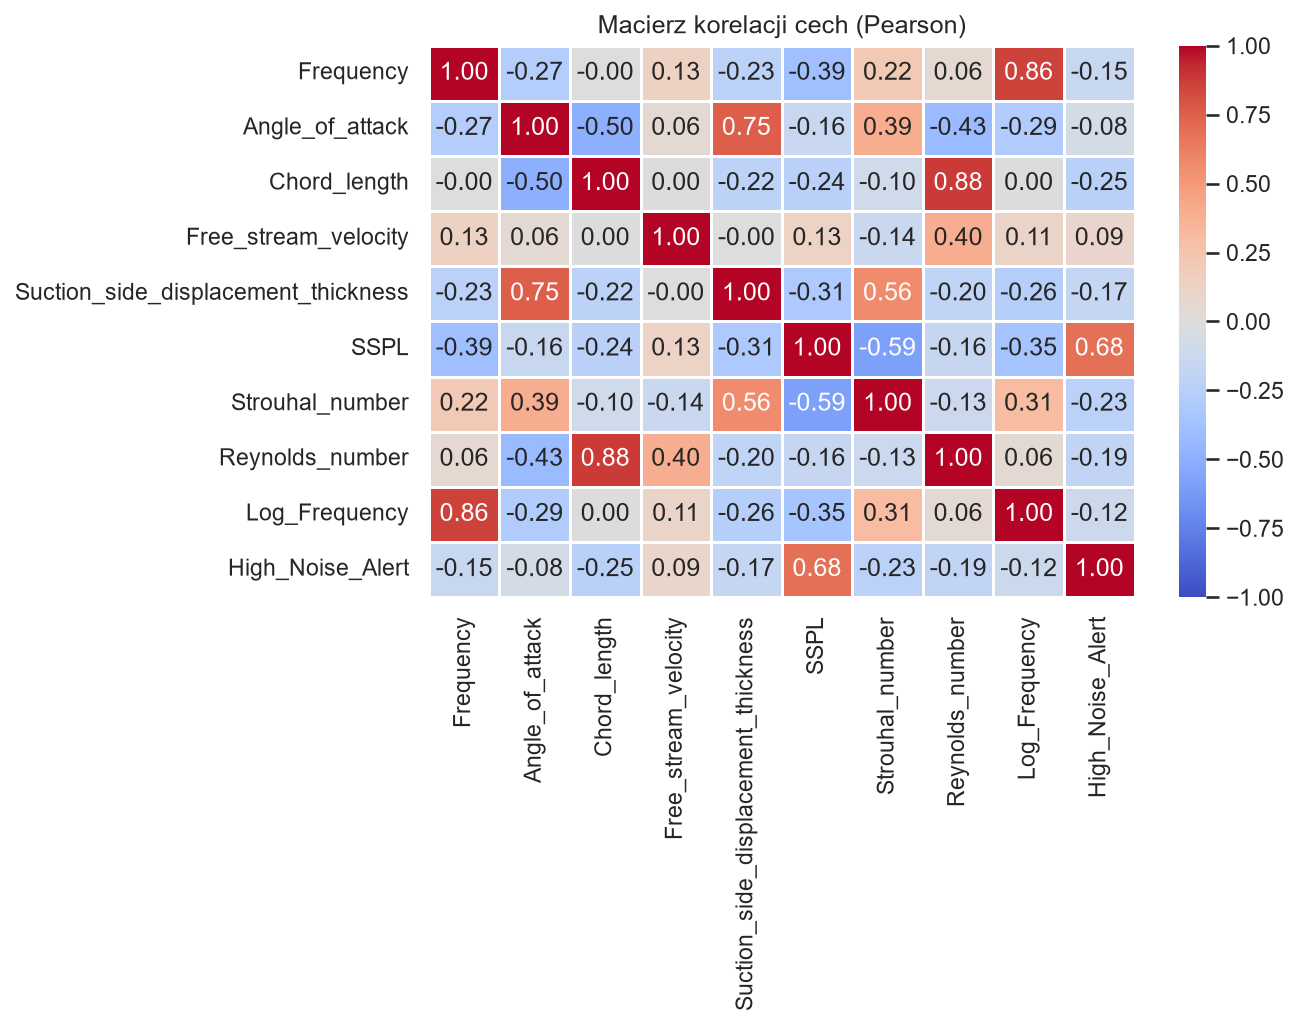

In [10]:
plt.figure(figsize=(9, 7))

# weryfikacja liniowych zaleznosci w celu identyfikacji kolinearnosci
correlation_matrix = df.select_dtypes(include=['float64', 'int64', 'int32']).corr()

sns.heatmap(
    correlation_matrix, 
    annot=True, 
    fmt=".2f", 
    cmap="coolwarm", 
    vmin=-1, 
    vmax=1, 
    linewidths=0.5
)
plt.title("Macierz korelacji cech (Pearson)")
plt.tight_layout()

# zapis wykresu do raportu
plt.savefig(figures_dir / "correlation_matrix.png")
plt.show()

**Wnioski z macierzy korelacji:**
1. Zmienna celu `SSPL` wykazuje najsilniejszą ujemną korelację z częstotliwością (`Frequency`, `Log_Frequency`) oraz grubością warstwy ściennej (`Suction_side_displacement_thickness`). Wskazuje to, że wysokie częstotliwości ulegają szybszemu tłumieniu akustycznemu.
2. Zmienne `Strouhal_number` oraz `Reynolds_number` wykazują silną korelację ze swoimi składowymi, co jest naturalnym efektem ich definicji fizycznej, ale pozwalają uchwycić efekty nieliniowe w modelach nieliniowych (np. w drzewach decyzyjnych).

#### 7.2. Rozkład poziomu ciśnienia akustycznego i fizyczna zależność od liczby Strouhala
Weryfikacja normalności rozkładu zmiennej zależnej oraz analiza nieliniowej zależności generowanego hałasu od bezwymiarowej częstotliwości wirowej ($St$).

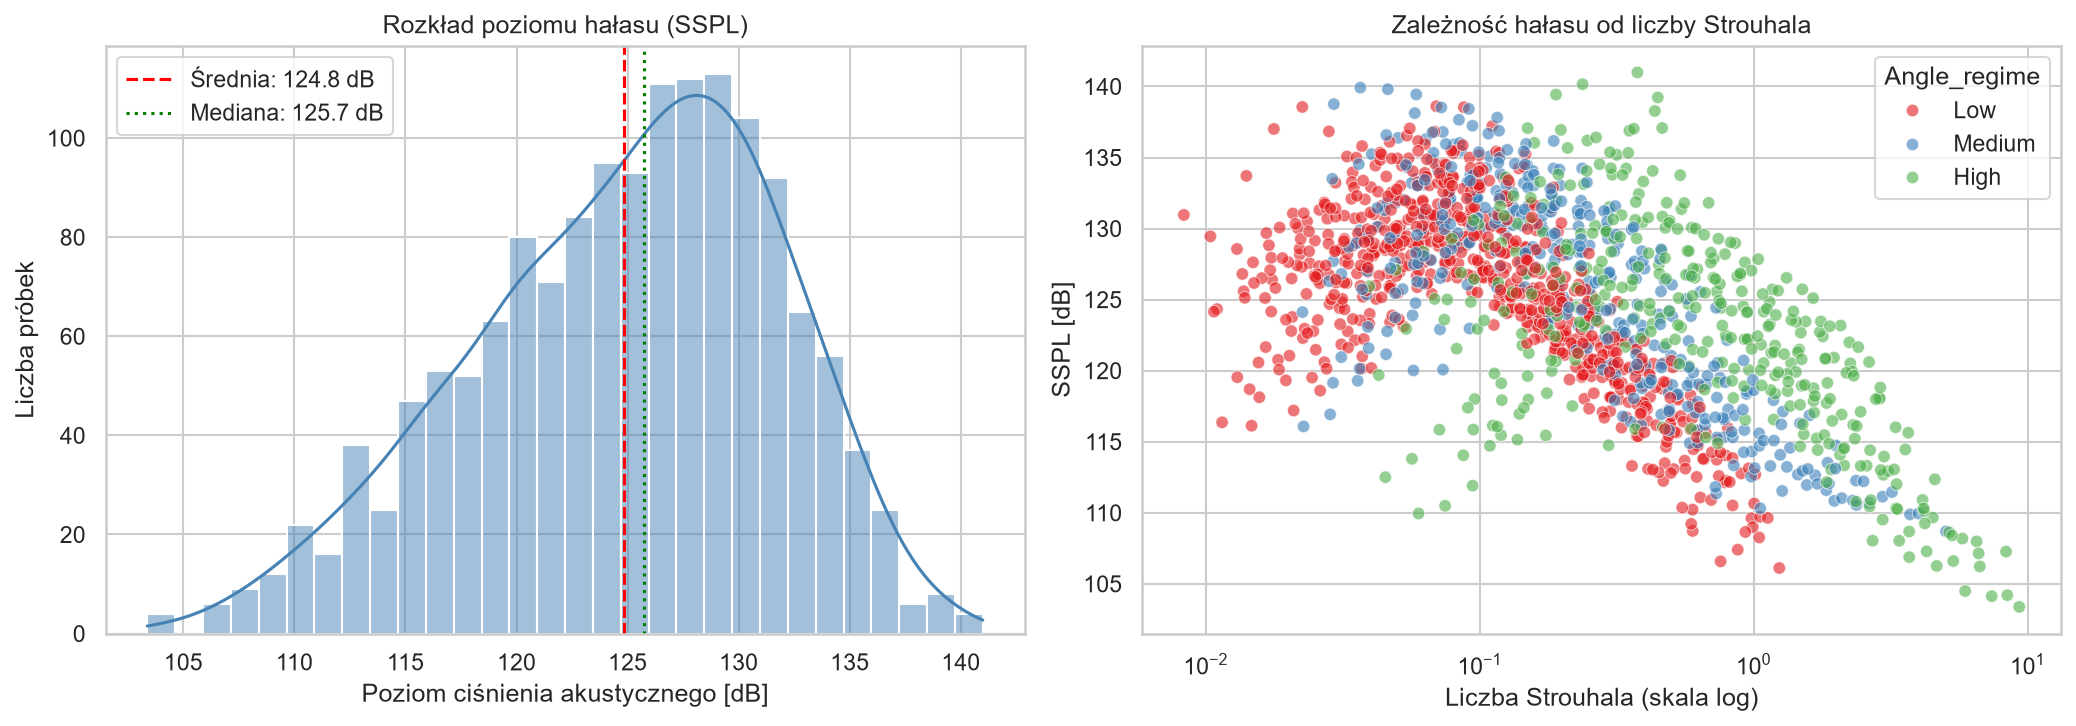

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# rozklad zmiennej celu
sns.histplot(df['SSPL'], kde=True, ax=axes[0], color='steelblue', bins=30)
axes[0].axvline(df['SSPL'].mean(), color='red', linestyle='--', label=f"Średnia: {df['SSPL'].mean():.1f} dB")
axes[0].axvline(df['SSPL'].median(), color='green', linestyle=':', label=f"Mediana: {df['SSPL'].median():.1f} dB")
axes[0].set_title("Rozkład poziomu hałasu (SSPL)")
axes[0].set_xlabel("Poziom ciśnienia akustycznego [dB]")
axes[0].set_ylabel("Liczba próbek")
axes[0].legend()

# zaleznosc akustyki od bezwymiarowej liczby strouhala w skali logarytmicznej
sns.scatterplot(
    data=df, 
    x='Strouhal_number', 
    y='SSPL', 
    hue='Angle_regime', 
    palette='Set1', 
    alpha=0.6, 
    ax=axes[1]
)
axes[1].set_xscale('log')
axes[1].set_title("Zależność hałasu od liczby Strouhala")
axes[1].set_xlabel("Liczba Strouhala (skala log)")
axes[1].set_ylabel("SSPL [dB]")

plt.tight_layout()
plt.savefig(figures_dir / "distribution_and_strouhal.png")
plt.show()

### 8. Agregacja danych i operacje na grupach (TK04)
W tym module realizujemy operacje grupowania (`groupby`) oraz budowy tabel przestawnych (`pivot_table`), aby ocenić zachowanie profilu aerodynamicznego w różnych warunkach pracy.

Badamy:
1. Emisję hałasu w zależności od reżimu kąta natarcia (`Angle_regime`).
2. Średnie ciśnienie akustyczne w ujęciu dwuwymiarowym: kąt natarcia vs. prędkość napływu.

In [12]:
# agregacja statystyczna po rezimach kata natarcia
regime_stats = df.groupby('Angle_regime', observed=False).agg(
    Probek=('SSPL', 'count'),
    Srednia_dB=('SSPL', 'mean'),
    Odchylenie_dB=('SSPL', 'std'),
    Mediana_dB=('SSPL', 'median'),
    Max_dB=('SSPL', 'max'),
    Min_dB=('SSPL', 'min'),
    Procent_zagrozenia=('High_Noise_Alert', lambda x: f"{x.mean() * 100:.1f}%")
).reset_index()

regime_stats

,Angle_regime,Probek,Srednia_dB,Odchylenie_dB,Mediana_dB,Max_dB,Min_dB,Procent_zagrozenia
0,Low,719,125.466434,6.174087,126.4130,138.607,106.111,24.3%
1,Medium,410,125.705661,7.228987,127.1925,139.918,108.689,34.4%
2,High,374,122.670414,7.393431,123.1775,140.987,103.380,16.0%


#### 8.1. Tabela przestawna: Kąt natarcia vs. Prędkość przepływu
Sprawdzamy, jak kombinacja prędkości wiatru w tunelu ($U_\infty$) i reżimu kąta natarcia wpływa na średni generowany hałas.

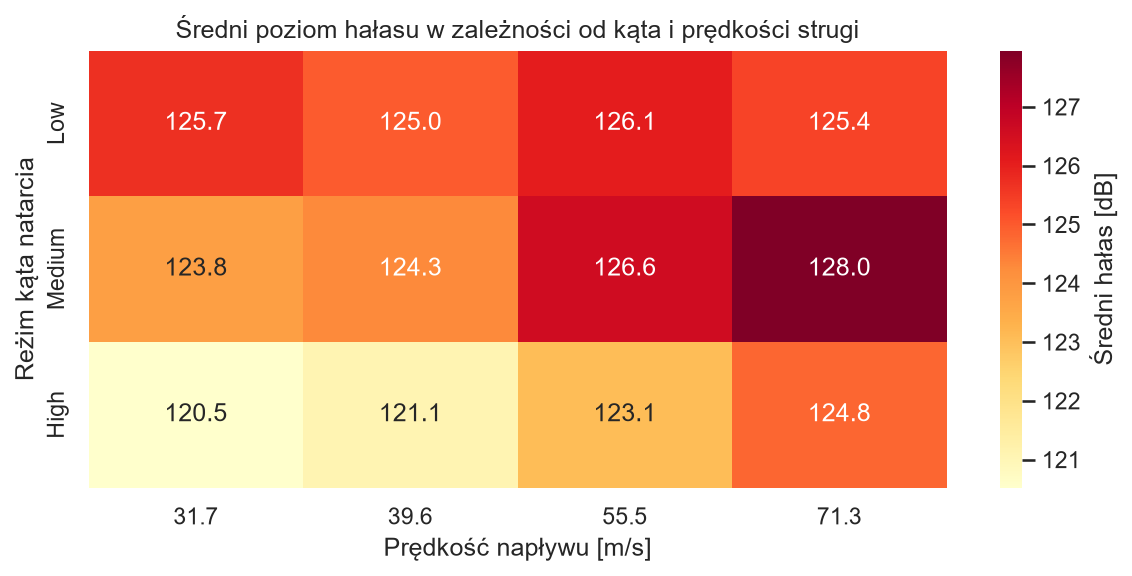

Free_stream_velocity,31.7,39.6,55.5,71.3
Angle_regime,,,,
Low,125.704105,124.981165,126.063473,125.355190
Medium,123.785098,124.288233,126.589443,127.959958
High,120.523872,121.097173,123.076250,124.813900


In [13]:
pivot_noise = df.pivot_table(
    values='SSPL', 
    index='Angle_regime', 
    columns='Free_stream_velocity', 
    aggfunc='mean',
    observed=False
)

plt.figure(figsize=(8, 4))
sns.heatmap(pivot_noise, annot=True, fmt=".1f", cmap="YlOrRd", cbar_kws={'label': 'Średni hałas [dB]'})
plt.title("Średni poziom hałasu w zależności od kąta i prędkości strugi")
plt.xlabel("Prędkość napływu [m/s]")
plt.ylabel("Reżim kąta natarcia")
plt.tight_layout()

plt.savefig(figures_dir / "pivot_angle_velocity.png")
plt.show()

pivot_noise

**Wnioski z analizy grupowej:**
1. Zgodnie z teorią mechaniki płynów, najwyższe średnie poziomy ciśnienia akustycznego obserwowane są dla dużych prędkości napływu ($71.3 \text{ m/s}$) przy jednoczesnych małych i umiarkowanych kątach natarcia.
2. W reżimie `High` (duże kąty natarcia $> 10^\circ$), pomimo występowania separacji strugi, całkowita energia akustyczna przesuwa się w stronę niższych częstotliwości, co powoduje spadek średniego ważonego poziomu decybeli w pasmach wysokich.